In [1]:
import os
import warnings

import geopandas as gpd
import matplotlib.pyplot as plt
import nivapy3 as nivapy
import pandas as pd
import seaborn as sn
from shapely.geometry import box, Polygon
from sqlalchemy import text
import contextily as ctx

plt.style.use("ggplot")
warnings.simplefilter("ignore")

In [2]:
eng = nivapy.da.connect_postgis()

Connection successful.


# Terrestrial inputs

## Notebook 01: Generate river outlets

**Run this notebook on one of the Hub's "high memory" machines (48 GB of RAM or greater).**

This notebook identifies river outlets to the coast within an area of interest.

We use the Hovedelv from the ELVIS river network to represent streams in Norway.

Previous version: The ELVIS dataset was initially filtered to only consider streams with a Strahler order greater than or equal to `min_order`. However, the order attribute includes NaNs, including for some big rivers. Instead, use hovedelv shapefile for now.

To identify outlet locations, "Havflate" polygons from Kartverket's `ArealdekkeFlate` layer in the N50 dataset are buffered by `buffer` metres and then intersected with the ELVIS streams. This gives one point near the outlet for every stream of interest.

Notes:
- The Hovedelv data do not include an "elvid" field, so this is generated and added here, but DOES NOT RELATE TO the elvids used in the main ELVIS river network.
- In riv_gdf, the field name for the vassdragsnumber is different for ELVIS river network and Hovedelv datasets ("vassdragnr" in ELVIS, "nbfVassNr" in the hovedelv). Hardcoded at the moment, so will need changing if using ELVIS instead of Hovedelv.

## 1. User inputs

In [11]:
# Projected CRS to work in
epsg = 25833  # 25833: ETRS89 / UTM zone 33N, suitable for all Norway

# ----------------------
# Define area of interest.

# Option 1: Provide lower-left corner of bounding box
# in the units of the CRS chosen above. Then provide width and height in km

# Test box
# xmin, ymin = 625000, 7600000
# width_km, height_km = 100, 150


# Option 2: Provide xmin, xmax, ymin, ymax directly

# Troms & Finnmark
# xmin, xmax = 523840, 1116205
# ymin, ymax = 7585560, 7940870

# Norway
xmin, xmax = -120000, 1160000
ymin, ymax = 6400000, 8000000

# ----------------------
# Buffer to apply to coastline to ensure rivers meet coast.
# In units of the CRS chosen above
buffer = 200

# ----------------------
# Folder to save output
# output_dir = "/home/jovyan/shared/common/JES/terrestrial_fluxes"
output_dir = "/home/jovyan/shared/common/norsink/spatial/coastal_drainage_basins"

# Create folders for results
for dir_name in ["shp", "csv"]:
    dir_path = os.path.join(output_dir, dir_name)
    if not os.path.exists(dir_path):
        os.makedirs(dir_path)

## 2. Setup

Create bounding box, and read in & clean sea and rivers data

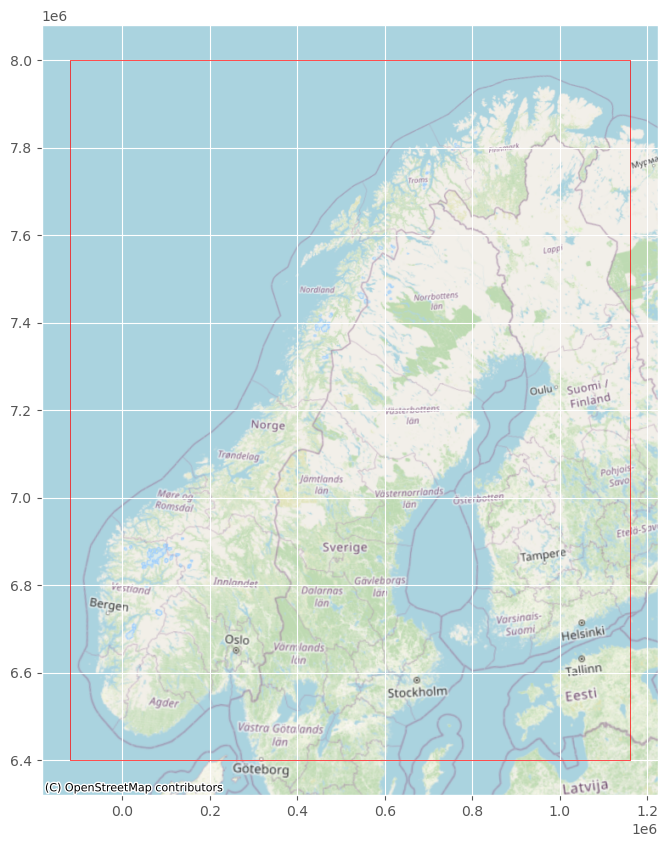

In [12]:
# Create bounding box & check it is correct
try:
    width_km
    height_km
    xmax = xmin + (width_km * 1000)
    ymax = ymin + (height_km * 1000)
    bbox = box(xmin, ymin, xmax, ymax)

except NameError:
    bbox = box(xmin, ymin, xmax, ymax)

# Plot
bbox_gdf = gpd.GeoDataFrame({'id': [1], 'geometry': [bbox]}, crs=f"EPSG: {epsg}")

# Plot the bounding box with a basemap
fig, ax = plt.subplots(figsize=(10, 10))
bbox_gdf.plot(ax=ax, color='none', edgecolor='red')

# Add a basemap
ctx.add_basemap(ax, crs=bbox_gdf.crs.to_string(), source=ctx.providers.OpenStreetMap.Mapnik)
plt.show()

In [13]:
# Read N50 surface cover and get just the sea polys
sea_gdf = (
    gpd.read_file(
        r"/home/jovyan/shared/common/JES/n50_kartdata/N50_Kartdata.gdb",
        layer="N50_ArealdekkeFlate",
    )
    .query("OBJTYPE == 'Havflate'")
    .to_crs(f"epsg:{epsg}")
    .clip(bbox)
)

# Dissolve sea polys and buffer
sea_gdf["dissolve"] = 1
sea_gdf = sea_gdf.dissolve(by="dissolve")
sea_gdf["geometry"] = sea_gdf["geometry"].buffer(buffer)

In [14]:
# Read rivers
# riv_gdf = (
#     nivapy.da.read_postgis("physical", "norway_nve_elvis_river_network_line", eng)
#     # .query("elveorden >= @min_order or elveorden.isnull()")
#     .to_crs(f"epsg:{epsg}")
#     .clip(bbox)
# )

riv_gdf = gpd.read_file(r"/home/jovyan/shared/common/01_datasets/spatial/norway_hovedelv/Elv_Hovedelv.shp")
riv_gdf = riv_gdf.to_crs(f"epsg:{epsg}").clip(bbox)

# Hovedelv rivers don't have an elvid. Add one
riv_gdf = riv_gdf.reset_index(drop=True)
riv_gdf.index.name = 'elvid'
riv_gdf = riv_gdf.reset_index(drop=False)
riv_gdf

,elvid,objType,nbfVassNr,elvenavn,elvelengde,nivaa,vassomr,uttakDato,ekspType,geometry
0,0,Hovedelv i kystfelt,022.32Z,Jåbekken,6237.44,3a,022,2025-05-15,NVEs nedlastningsløsning,"LINESTRING Z (57647.145 6455598.162 0, 57646.7..."
1,1,Hovedelv i kystfelt,022.43Z,bekk fra Hoggandvikvatna,8130.39,3a,022,2025-05-15,NVEs nedlastningsløsning,"LINESTRING Z (47038.739 6461837.561 0, 47124.5..."
2,2,Hovedelv i kystfelt,022.3Z,Harkmarkelva,13007.37,2a,022,2025-05-15,NVEs nedlastningsløsning,"LINESTRING Z (64236.222 6457573.243 0, 64208.3..."
3,3,Sideelv,022.A2Z,Sodlandsbekken,4133.95,3a,022,2025-05-15,NVEs nedlastningsløsning,"LINESTRING Z (58423.944 6459964.632 0, 58391.3..."
4,4,Sideelv,023.A1AZ,bekk fra Fasselandsvatnet,4987.93,4a,023,2025-05-15,NVEs nedlastningsløsning,"LINESTRING Z (49021.852 6462572.91 0, 49020.87..."
...,...,...,...,...,...,...,...,...,...,...
6274,6274,Hovedelv i kystfelt,231.6Z,Mehamnelva,20548.55,2a,231,2025-05-15,NVEs nedlastningsløsning,"LINESTRING Z (959991.984 7914678.39 0, 959987...."
6275,6275,Hovedelv i kystfelt,231.64Z,Futelva,27338.28,3a,231,2025-05-15,NVEs nedlastningsløsning,"LINESTRING Z (962020.54 7914383.75 0, 962027.0..."
6276,6276,Hovedelv i kystfelt,231.61Z,Sørfjordelva,12500.84,3a,231,2025-05-15,NVEs nedlastningsløsning,"LINESTRING Z (958559.394 7920819.87 0, 958527...."
6277,6277,Hovedelv i kystfelt,231.9Z,Risdalselva,13065.43,2a,231,2025-05-15,NVEs nedlastningsløsning,"LINESTRING Z (982947.57 7922956.437 0, 982950...."


### Save bounding box, rivs & coastline used

In [15]:
bbox_gdf.to_file(os.path.join(output_dir, "shp", "bounding_box.shp"))
sea_gdf.to_file(os.path.join(output_dir, "shp", "sea.shp"))
riv_gdf.to_file(os.path.join(output_dir, "shp", "rivers.shp"))

### Plot

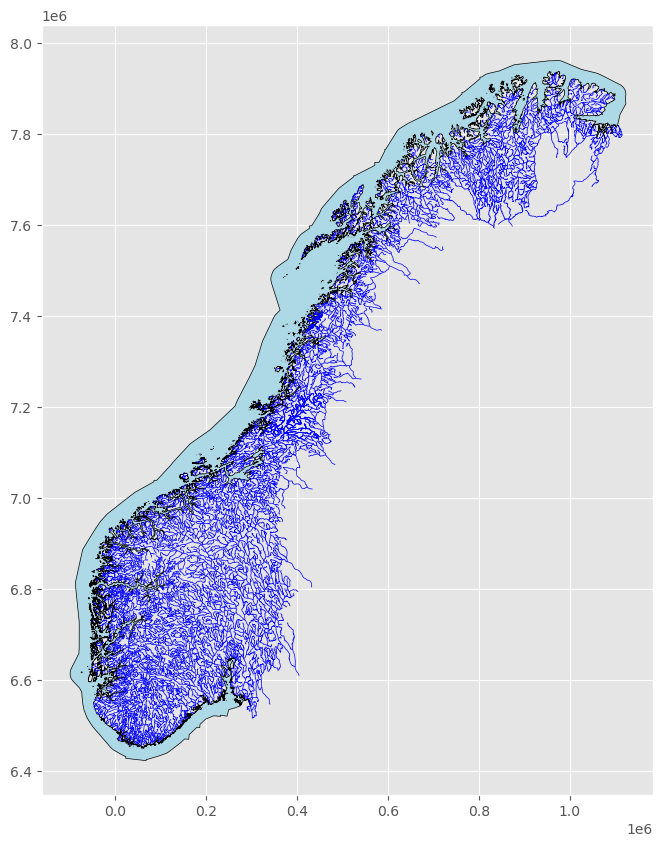

In [16]:
# Plot
%matplotlib inline
plt.close('all')
ax = sea_gdf.plot(facecolor="lightblue", edgecolor="k", lw=0.5, figsize=(10, 10))
riv_gdf.plot(ax=ax, lw=0.5, edgecolor="blue")
plt.show()

## 3. Identify river outlets

In [17]:
# Calculate intersections
outlet_gdf = sea_gdf.set_geometry(sea_gdf.boundary).overlay(
    riv_gdf, keep_geom_type=False
)
outlet_gdf = outlet_gdf.explode(index_parts=True).reset_index(drop=True)
outlet_gdf = outlet_gdf.drop_duplicates(subset="elvid")
outlet_gdf["easting"] = outlet_gdf.geometry.x
outlet_gdf["northing"] = outlet_gdf.geometry.y

# Add lat and lon columns
outlet_gdf['latitude'] = outlet_gdf.to_crs(epsg=4326).geometry.y
outlet_gdf['longitude'] = outlet_gdf.to_crs(epsg=4326).geometry.x

# cols for elvis rivers
# outlet_df = outlet_gdf[["elvid", "vassdragnr", "easting", "northing", "latitude", "longitude"]]

# cols for hovedelv
outlet_df = outlet_gdf[["elvid", "nbfVassNr", "easting", "northing", "latitude", "longitude"]]

print(
    f"{len(outlet_df)} outlets for streams identified within the area of interest."
)

outlet_df.head()

2079 outlets for streams identified within the area of interest.


,elvid,nbfVassNr,easting,northing,latitude,longitude
0,0,022.32Z,57644.761863,6.455798e+06,58.022290,7.502217
1,1,022.43Z,51780.981208,6.457149e+06,58.028450,7.401257
2,2,022.3Z,64044.032832,6.457637e+06,58.044984,7.606244
3,6,022.4Z,52223.007045,6.459131e+06,58.046539,7.404913
4,10,023.22Z,34091.759523,6.456831e+06,58.007450,7.105193


### Save

In [18]:
# Save
outlet_gdf.to_file(os.path.join(output_dir, "shp", "outlets_all.shp"))
outlet_df.to_csv(os.path.join(output_dir, "csv", f"outlets_all.csv"), index=False)

### Plot

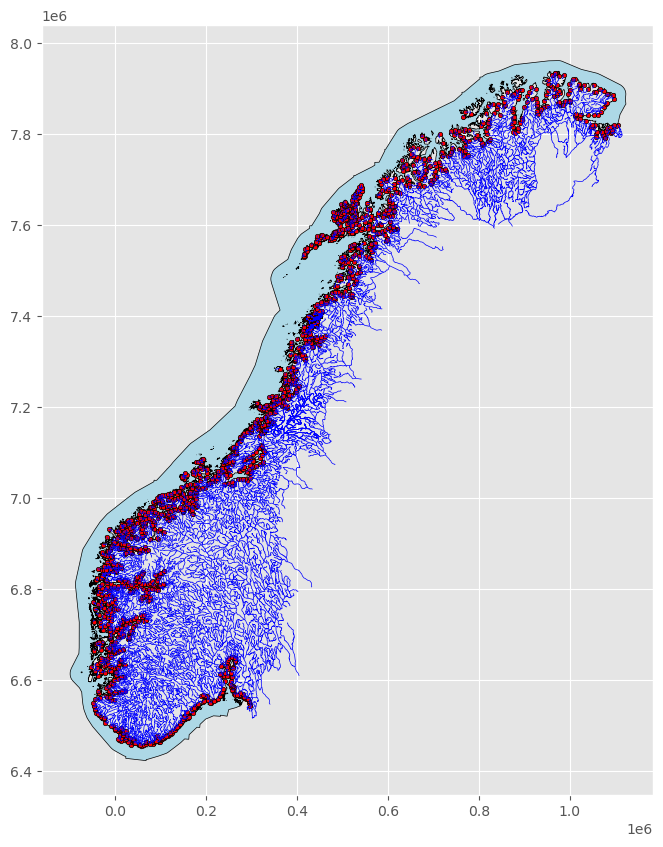

In [19]:
ax = sea_gdf.plot(facecolor="lightblue", edgecolor="k", lw=0.5, figsize=(10, 10))
riv_gdf.plot(ax=ax, lw=0.5, edgecolor="blue")
outlet_gdf.plot(ax=ax, marker="o", color="red", edgecolor="black", markersize=10)
plt.show()